# 視覚言語モデルによる画像質問応答

視覚言語モデル [Qwen3.5-4B](https://huggingface.co/Qwen/Qwen3.5-4B) を手元の実行環境に読み込み、画像の前処理と質問応答を試します。

In [1]:
%pip install -q -U torch torchvision transformers accelerate  # モデルの読み込みと推論
%pip install -q pillow scikit-image  # 画像の加工とサンプル画像

## モデルの準備

CUDA 対応 GPU を使います。Colab では「ランタイム」→「ランタイムのタイプを変更」から GPU を選んでください。T4（16 GB）を想定し、モデルを FP16 で読み込み、画像の画素数を抑えて推論します。初回はモデルのダウンロードに約10 GBの空き容量とインターネット接続が必要です。

In [2]:
import torch
from transformers import AutoProcessor, Qwen3_5ForConditionalGeneration

model_id = "Qwen/Qwen3.5-4B"
device = "cuda"
dtype = torch.float16  # T4 でも使える数値型
print("実行先:", torch.cuda.get_device_name(), "/ モデルの数値型:", dtype)

# 画素数の上限を256×256、下限を32×32にして、画像の処理量を抑える
processor = AutoProcessor.from_pretrained(
    model_id, size={"shortest_edge": 32 * 32, "longest_edge": 256 * 256}
)

実行先: Tesla T4 / モデルの数値型: torch.float16


## 元画像

`scikit-image` に同梱された NASA の宇宙飛行士の画像を使います。
出典：[サンプル画像の説明](https://scikit-image.org/docs/stable/api/skimage.data.html#skimage.data.astronaut)。

画像の大きさ: (512, 512) / 色の形式: RGB


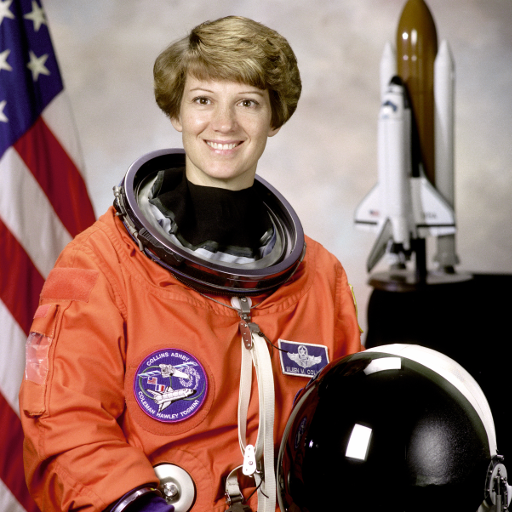

In [3]:
from PIL import Image
from skimage import data
from IPython.display import display

image = Image.fromarray(data.astronaut()).convert("RGB")
print("画像の大きさ:", image.size, "/ 色の形式:", image.mode)
display(image)

## 画像から特徴ベクトルへの変換

`processor.image_processor` は、画像のリサイズ・正規化・パッチへの分割を行う前処理です。`processor` は質問文のトークン化も行い、画像と質問をモデルの入力にまとめます。まず、その形状を確認します。

In [4]:
def prepare_inputs(target, question):
    """画像と質問のモデル入力への変換"""
    messages = [
        {"role": "system", "content": "あなたは AI アシスタントです。質問には、簡潔に日本語で答えてください。"},
        {"role": "user", "content": [
            {"type": "image", "image": target},
            {"type": "text", "text": question},
        ]},
    ]
    return processor.apply_chat_template(
        messages,
        add_generation_prompt=True,
        tokenize=True,
        return_dict=True,
        return_tensors="pt",
        enable_thinking=False,  # 長い推論文の生成を省く
    )

question = "人物は何を着ていますか？"
inputs = prepare_inputs(image, question)

# テキストと画像プレースホルダーをトークンIDに変換したシーケンスの形状
print("input_ids (バッチサイズ, トークン数):", tuple(inputs["input_ids"].shape))

# パディング等を区別するためのマスクの形状（通常 input_ids と同じ長さ）
print("attention_mask (バッチサイズ, トークン数):", tuple(inputs["attention_mask"].shape))

# マルチモーダル（画像やテキスト）のトークン種別を区別するIDの形状
print("mm_token_type_ids (バッチサイズ, トークン数):", tuple(inputs["mm_token_type_ids"].shape))

# 前処理・パッチ分割された画像データの形状
print("pixel_values (総パッチ数, 1パッチあたりの画素値数):", tuple(inputs["pixel_values"].shape))

# 画像の3次元的な配置（時間、高さ、幅のパッチ数）を表す情報の形状
print("image_grid_thw (バッチサイズ, 3次元要素):", tuple(inputs["image_grid_thw"].shape))

input_ids (バッチサイズ, トークン数): (1, 109)
attention_mask (バッチサイズ, トークン数): (1, 109)
mm_token_type_ids (バッチサイズ, トークン数): (1, 109)
pixel_values (総パッチ数, 1パッチあたりの画素値数): (256, 1536)
image_grid_thw (バッチサイズ, 3次元要素): (1, 3)


次にモデルを読み込みましょう。

In [5]:
model = Qwen3_5ForConditionalGeneration.from_pretrained(
    model_id, dtype=dtype, device_map=device, attn_implementation="sdpa"
).eval()

Loading weights:   0%|          | 0/723 [00:00<?, ?it/s]

In [6]:
# 画像エンコーダのネットワーク構造
print(model.model.visual)

Qwen3_5VisionModel(
  (patch_embed): Qwen3_5VisionPatchEmbed(
    (proj): Conv3d(3, 1024, kernel_size=(2, 16, 16), stride=(2, 16, 16))
  )
  (pos_embed): Embedding(2304, 1024)
  (rotary_pos_emb): Qwen3_5VisionRotaryEmbedding()
  (blocks): ModuleList(
    (0-23): 24 x Qwen3_5VisionBlock(
      (norm1): LayerNorm((1024,), eps=1e-06, elementwise_affine=True, bias=True)
      (norm2): LayerNorm((1024,), eps=1e-06, elementwise_affine=True, bias=True)
      (attn): Qwen3_5VisionAttention(
        (qkv): Linear(in_features=1024, out_features=3072, bias=True)
        (proj): Linear(in_features=1024, out_features=1024, bias=True)
      )
      (mlp): Qwen3_5VisionMLP(
        (linear_fc1): Linear(in_features=1024, out_features=4096, bias=True)
        (linear_fc2): Linear(in_features=4096, out_features=1024, bias=True)
        (act_fn): GELUTanh()
      )
    )
  )
  (merger): Qwen3_5VisionPatchMerger(
    (norm): LayerNorm((1024,), eps=1e-06, elementwise_affine=True, bias=True)
    (linear_fc1

画像ネットワークは、自己注意機構（`attn`）、フィードフォワード層（`mlp`）からなる Transformer エンコーダです。

In [7]:
# 画像エンコーダの推論
with torch.inference_mode():
    vision_outputs = model.get_image_features(
        pixel_values=inputs["pixel_values"].to(device, dtype=dtype),
        image_grid_thw=inputs["image_grid_thw"].to(device),
        return_dict=True,
    )

print("ViT の出力（パッチ数, 次元）:", tuple(vision_outputs.last_hidden_state.shape))
image_features = vision_outputs.pooler_output[0]  # 1枚目の画像の統合後の特徴ベクトル
print("言語モデルへの入力（画像トークン数, 次元）:", tuple(image_features.shape))

ViT の出力（パッチ数, 次元）: (256, 1024)
言語モデルへの入力（画像トークン数, 次元）: (64, 2560)


ViT の出力は `(256, 1024)`、2×2パッチの統合後は `(64, 2560)` です。64個の画像トークンとして渡します。各ベクトルの2560次元は、言語モデルのトークン埋め込みと同じ次元です。


## 画像に基づく回答の生成

モデルは `input_ids` 内の画像トークンの位置に、この特徴ベクトルを入れ、質問文と合わせて回答を生成します。

In [8]:
def generate_answer(model_inputs):
    """モデル入力からの回答文の生成"""
    model_inputs = model_inputs.to(device, dtype=dtype)
    with torch.inference_mode():
        output_ids = model.generate(
            **model_inputs, max_new_tokens=256, do_sample=False
        )
    # 出力には入力文も含まれるため、新たに生成された部分だけを文字列へ戻す
    answer_ids = output_ids[0, model_inputs["input_ids"].shape[1]:]
    return processor.decode(answer_ids, skip_special_tokens=True).strip()

In [9]:
question = "画像には何が映っていますか？"
generate_answer(prepare_inputs(image, question))

'画像には、オレンジ色の宇宙服を着た女性アストロナーバーが映っています。彼女は笑顔でカメラを見つめ、背景にはアメリカ国旗とスペースシャトルが描かれています。また、前景には宇宙服のヘルメットが置かれています。'

物体ハルシネーションが起こるかを確かめてみましょう。

In [10]:
question = "画像に映るスペースシャトルの模型の隣にある地球儀は何色ですか？"
print("質問:", question)
print("回答:", generate_answer(prepare_inputs(image, question)))

質問: 画像に映るスペースシャトルの模型の隣にある地球儀は何色ですか？
回答: 青です。


画像に地球儀は存在しませんが、「青」だと答えています。

## まとめ

VLM の画像の前処理やモデルの動作を確認しました。

参考：[Qwen3.5-4B のモデルカード](https://huggingface.co/Qwen/Qwen3.5-4B)、[Transformers の Qwen3.5](https://huggingface.co/docs/transformers/model_doc/qwen3_5)。